# Clustering Artikel Klarifikasi Hoaks Komdigi

Latihan ini menerapkan K-Means pada teks artikel dari `komdigi_hoaks.csv`. Teks judul, ringkasan, dan isi artikel diubah menjadi fitur TF-IDF. Jumlah cluster dibandingkan menggunakan SSE/elbow dan hasil cluster divisualisasikan memakai SVD 2D.

K-Means bersifat unsupervised: kolom `topics` tidak dipakai untuk membentuk cluster dan hanya tersedia untuk interpretasi lanjutan. `topics` adalah topik artikel, bukan label klaim benar atau salah.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

# Cari dataset dari direktori kerja notebook hingga root proyek.
data_path = next(
    (
        parent / "data" / "komdigi_hoaks.csv"
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "data" / "komdigi_hoaks.csv").is_file()
    ),
    None,
)
if data_path is None:
    raise FileNotFoundError("File komdigi_hoaks.csv tidak ditemukan.")

df = pd.read_csv(data_path)
print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran dataset:", df.shape)

# URL dipakai untuk menghapus artikel berulang. topics hanya untuk interpretasi hasil.
df = df.drop_duplicates(subset="url", keep="first").copy()
text_columns = ["title", "excerpt", "body_text"]
df[text_columns] = df[text_columns].fillna("").astype(str)
df["article_text"] = (
    df[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Ubah artikel menjadi vektor TF-IDF yang dapat digunakan K-Means.
vectorizer = TfidfVectorizer(
    max_features=5000,
    min_df=2,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X = vectorizer.fit_transform(df["article_text"])
print("Jumlah artikel setelah deduplikasi:", len(df))
print("Ukuran matriks TF-IDF:", X.shape)
print("Contoh fitur:", vectorizer.get_feature_names_out()[:20])

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran dataset: (4176, 13)
Jumlah artikel setelah deduplikasi: 4162
Ukuran matriks TF-IDF: (4162, 5000)
Contoh fitur: ['00' '000' '000 per' '01' '02' '03' '04' '05' '06' '07' '08' '09' '10'
 '100' '11' '12' '13' '14' '15' '16']


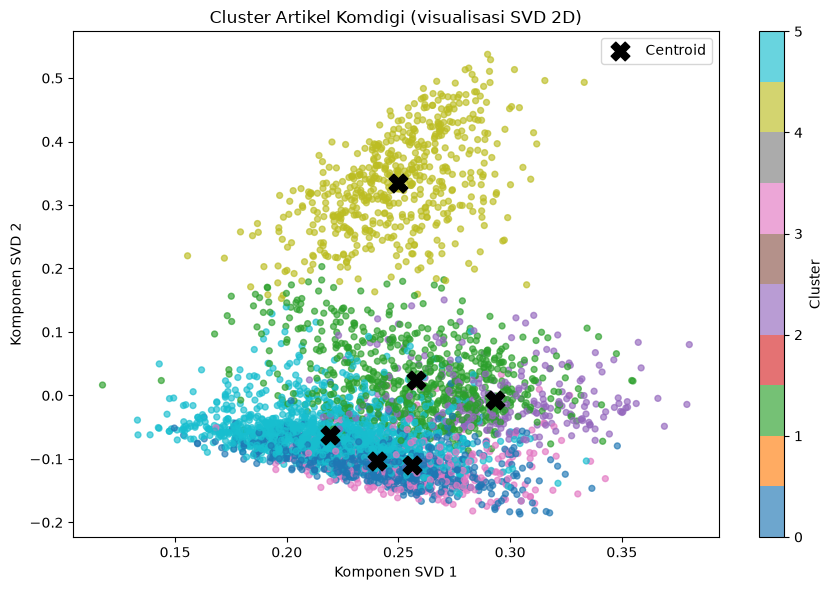

Jumlah artikel per cluster:
cluster
0     809
1     709
2     284
3     373
4     559
5    1428
Name: count, dtype: int64
Variansi yang dijelaskan SVD: 0.0247


In [2]:
# Clustering K-Means pada representasi TF-IDF.
# K-Means tidak menggunakan topics saat membentuk cluster.
n_clusters = 6
cl_kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
cluster_labels = cl_kmeans.fit_predict(X)
df["cluster"] = cluster_labels

# Reduksi dimensi hanya untuk visualisasi; clustering tetap dilakukan pada TF-IDF.
svd = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd.fit_transform(X)
centers_2d = svd.transform(cl_kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1], c=cluster_labels, cmap="tab10", s=18, alpha=0.65
)
plt.scatter(
    centers_2d[:, 0], centers_2d[:, 1],
    c="black", marker="X", s=180, label="Centroid",
)
plt.xlabel("Komponen SVD 1")
plt.ylabel("Komponen SVD 2")
plt.title("Cluster Artikel Komdigi (visualisasi SVD 2D)")
plt.legend()
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print("Jumlah artikel per cluster:")
print(df["cluster"].value_counts().sort_index())
print("Variansi yang dijelaskan SVD:", round(svd.explained_variance_ratio_.sum(), 4))

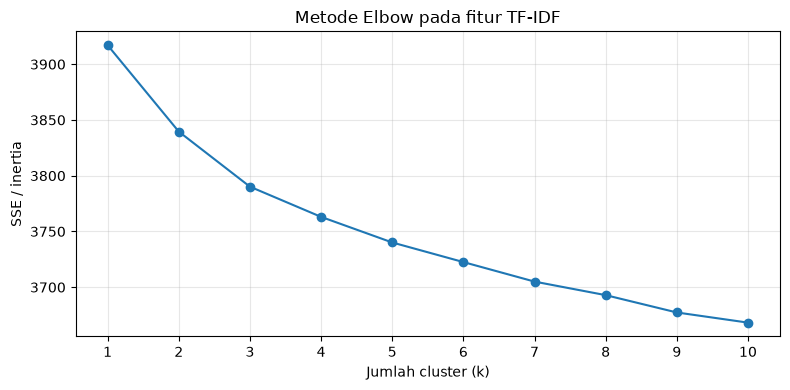

In [3]:
# SSE (inertia) dan metode elbow untuk membandingkan jumlah cluster.
sse = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X)
    sse.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_values, sse, "o-")
plt.xticks(list(k_values))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("SSE / inertia")
plt.title("Metode Elbow pada fitur TF-IDF")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Nilai SSE untuk setiap nilai k.
for k, sse_value in zip(k_values, sse):
    print(f"k={k}; SSE={sse_value:.4f}")

k=1; SSE=3917.0399
k=2; SSE=3839.5469
k=3; SSE=3790.1496
k=4; SSE=3763.0697
k=5; SSE=3740.1047
k=6; SSE=3722.5226
k=7; SSE=3705.0104
k=8; SSE=3692.8731
k=9; SSE=3677.3265
k=10; SSE=3668.2180
